# Plot the time series of each simulation 

In [1]:
import numpy as np
import os
import astropy.units as u
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable

import h5py
import json

from field_config import field_labels, field_lims, field_scales

In [2]:
bowshock_config_dict = json.load(open("../config/bowshock_config.json"))
bowshock_config = bowshock_config_dict["config"]
shock_labels = bowshock_config_dict["shock_labels"]

fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/crshock"

### Plotting shock parameter in each row, model in each column

The angular dependence is plotted using a cmap color scheme following the bow shock colors

In [3]:
params = ["encr", "shma", "crac", "geff"]
shock_type = "outer"

theta_ranges_sim = [(0, 10), (10,20),(20,30), (30, 45), (45,60), (60,75), (75,90), (90,120), (120,150),(150,180)]
theta_ranges_cmap = cm.viridis
theta_ranges_norm = mcolors.Normalize(vmin=0, vmax=180, clip=False)

#### Velocity dependence plots

In [4]:
param_textpos = {
    "encr" : 3e-11,
    "shma" : 30,
    "crac" : 0.175,
    "geff" : 1.7
}

fig_type_dir = os.path.join(fig_dir, "vels")
if not os.path.exists(fig_type_dir):
    os.mkdir(fig_type_dir)

30 [  0.          10.01313255  20.03861553  30.03247859  40.01123843
  50.00108412  60.00378535  70.04026171  80.00670532  90.01462883
 100.00079513 110.03960663 120.01956819 130.039198   140.03669921
 150.01793419 150.01793419 160.00135086 170.0129363  180.02425114
 190.00344715 200.03517702 210.02657818] kyr
60 [  0.          10.042629    20.03613084  30.04066087  40.03940922
  50.00746852  60.01134361  70.04235667  80.00832202  90.00900669
 100.02348187 110.01408412 120.00450663 130.00299801 140.02660998
 150.02741253 160.01381143 170.00689913 180.00950384 190.01377018
 200.02248319 220.02575834 230.03769754] kyr
100 [  0.          10.00650608  20.02610503  30.01170653  40.04171596
  50.00496255  60.01856615  70.0263628   80.01757816  90.02837578
 100.000902   110.01835958 120.0012255  130.00283528 140.01892275
 150.00114544 160.03434253 170.02236244] kyr
30 [  0.          10.01313255  20.03861553  30.03247859  40.01123843
  50.00108412  60.00378535  70.04026171  80.00670532  90.014

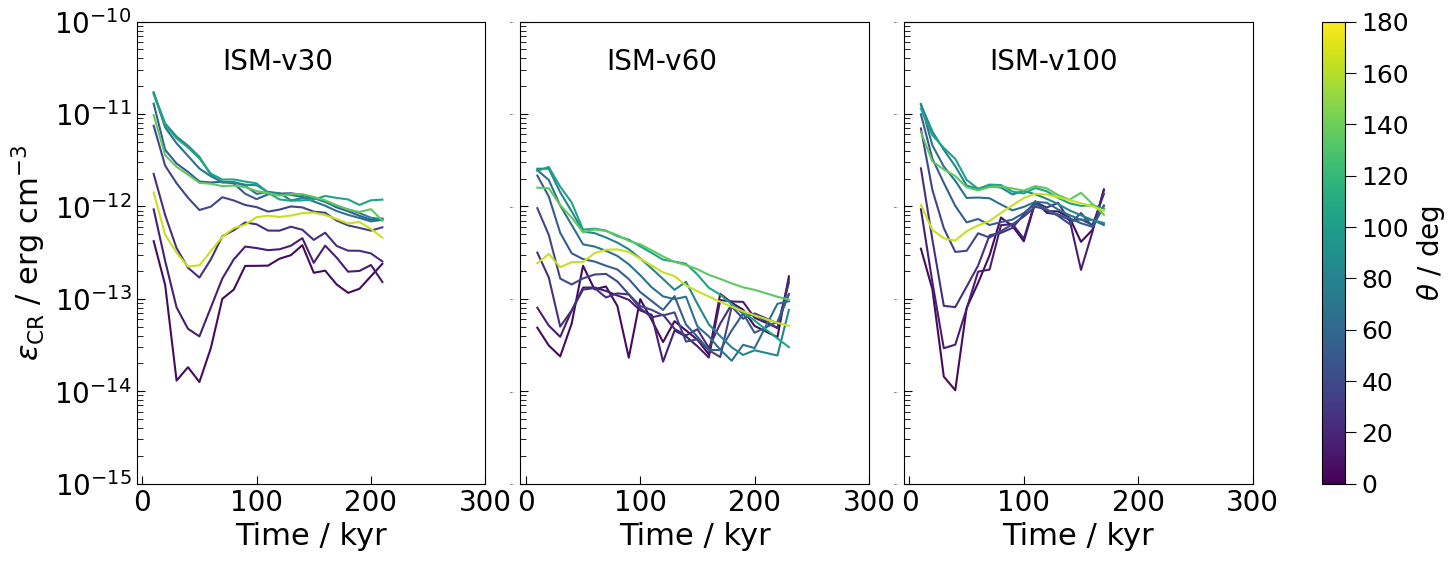

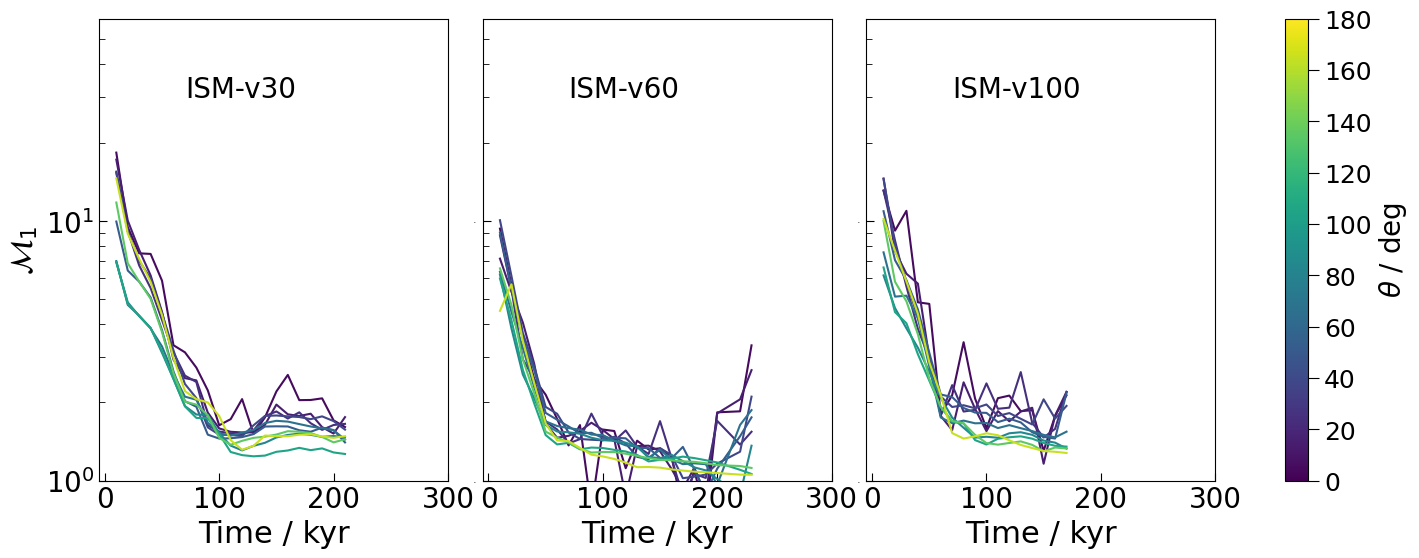

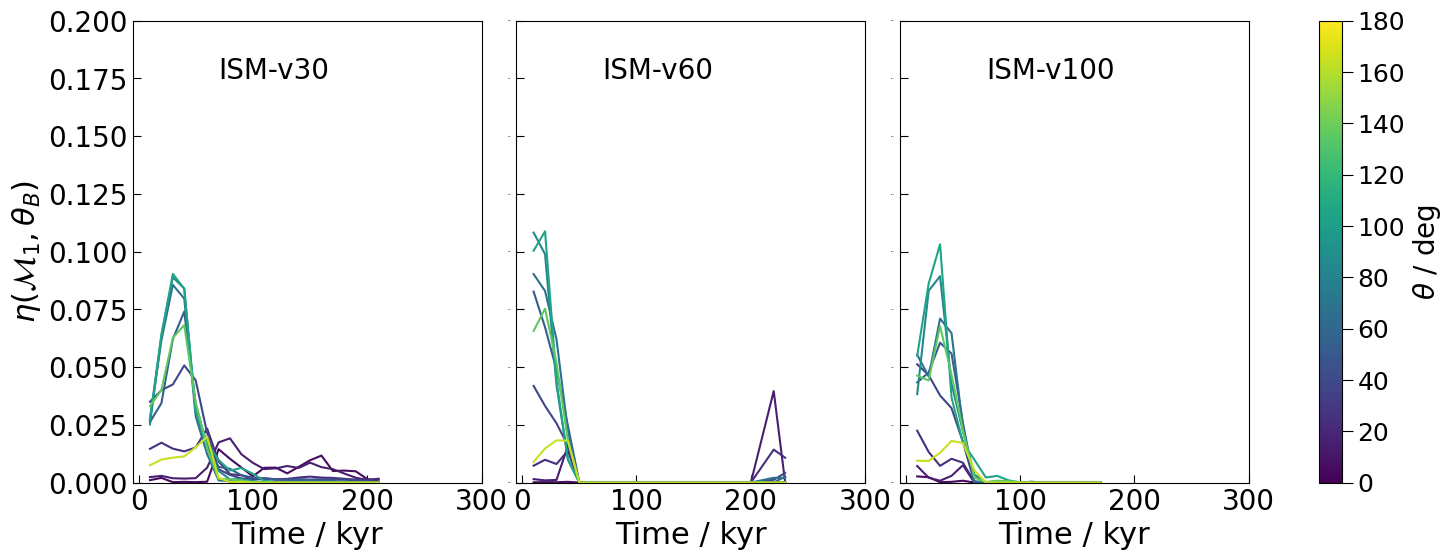

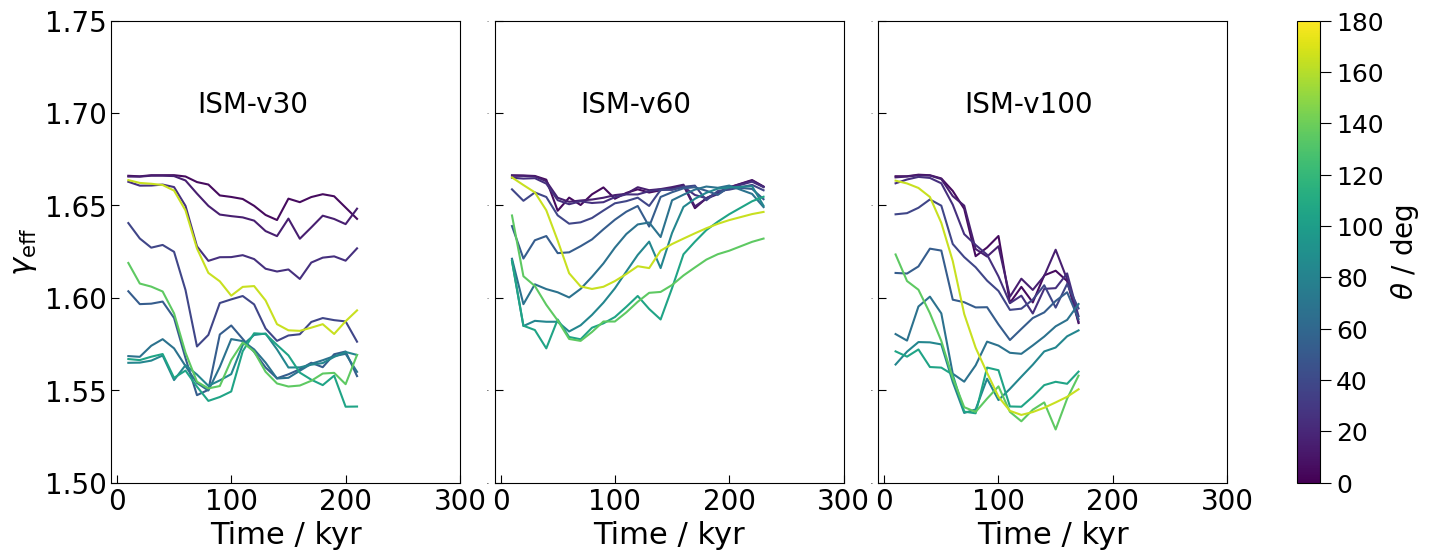

In [5]:
for p in params:
    fig = plt.figure(figsize=(18,6))
    gs = fig.add_gridspec(1, 3, hspace=0.1, wspace=0.1)
    axs = gs.subplots(sharex=True, sharey=False)

    with h5py.File(f"../data/polar_time_series_{shock_type}.h5", "r") as f:
        for ibs, vstar in enumerate([30, 60, 100]):
            bs_name = f"ISM-v{vstar}"
            
            times = (f[bs_name]["times"][()] * u.s).to(u.kyr)
            print(vstar, times)
            param_arr = f[bs_name][p][()]
            
            for itr, theta_range in enumerate(theta_ranges_sim):
                theta_mean = 0.5 * (theta_range[0] + theta_range[1])
                pl = axs[ibs].plot(times, param_arr[:,itr], color=theta_ranges_cmap(theta_ranges_norm(theta_mean)))


            # labels
            axs[ibs].set_xlabel("Time / kyr", fontsize=22)
            if ibs == 0:
                axs[ibs].set_ylabel(field_labels[p], fontsize=22)

            # limits
            axs[ibs].set_xlim([-5, 300])
            axs[ibs].set_ylim(field_lims[p])

            # scales
            axs[ibs].set_yscale(field_scales[p])

            # ticks
            axs[ibs].tick_params(axis='x', direction="in", which='major', size=6, labelsize=20)
            axs[ibs].tick_params(axis='x', direction="in", which='minor', size=4, labelsize=16)

            # for y
            if ibs == 0:
                axs[ibs].tick_params(axis='y', direction="in", which='major', size=6, labelsize=20)
                axs[ibs].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=16)
            else:
                axs[ibs].tick_params(axis='y', direction="in", which='major', size=6, labelsize=0)
                axs[ibs].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=0)

            axs[ibs].annotate(f"{bs_name}", xy=(70, param_textpos[p]), fontsize=20, bbox=dict(facecolor='white', edgecolor='none'))

    # colorbar
    sm = cm.ScalarMappable(cmap=theta_ranges_cmap, norm=theta_ranges_norm)
    cbar = fig.colorbar(sm, ax=axs.ravel().tolist())
    cbar.ax.set_ylabel(r"$\theta$ / deg", fontsize=20)
    cbar.ax.tick_params(axis='both', which='major', size=8, labelsize=18)
    cbar.ax.tick_params(axis='both', which='minor', size=6, labelsize=18)

    fig.savefig(
        os.path.join(fig_type_dir, f"timeseries_{shock_type}_{p}.pdf"),
        dpi=200,
        bbox_inches="tight",
    )


#### Diffusion-dependent plots

In [6]:
param_textpos = {
    "encr" : 3e-11,
    "shma" : 30,
    "crac" : 0.175,
    "geff" : 1.7
}

fig_type_dir = os.path.join(fig_dir, "diffs")
if not os.path.exists(fig_type_dir):
    os.mkdir(fig_type_dir)

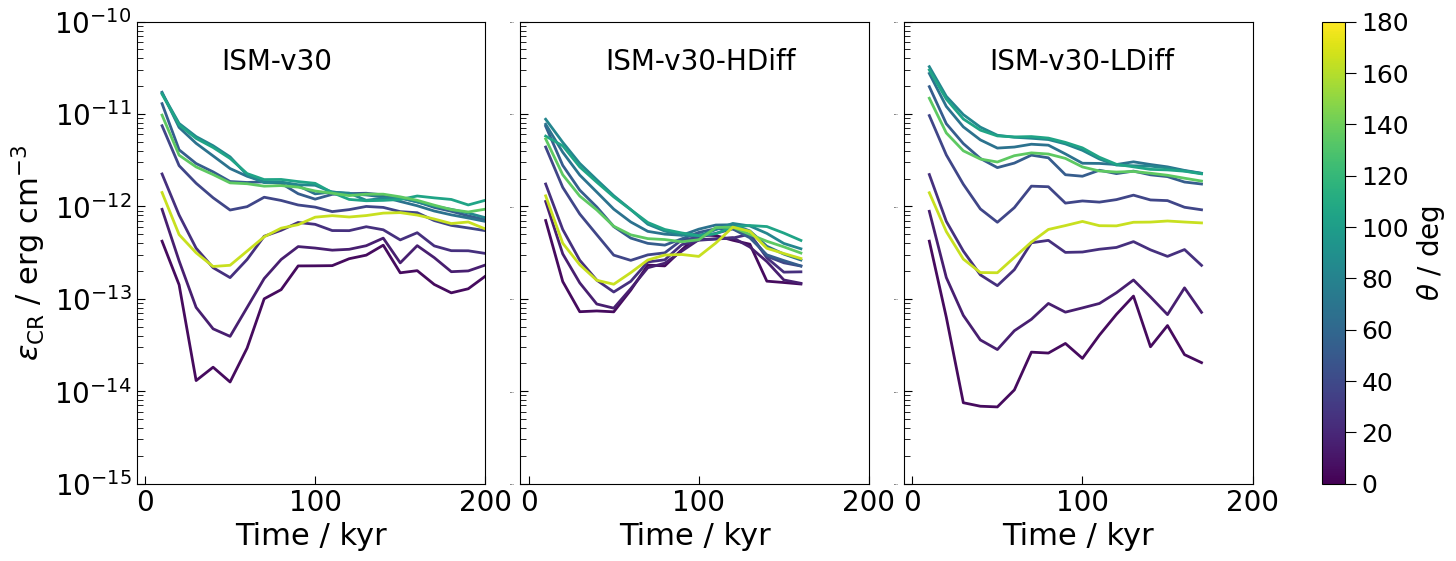

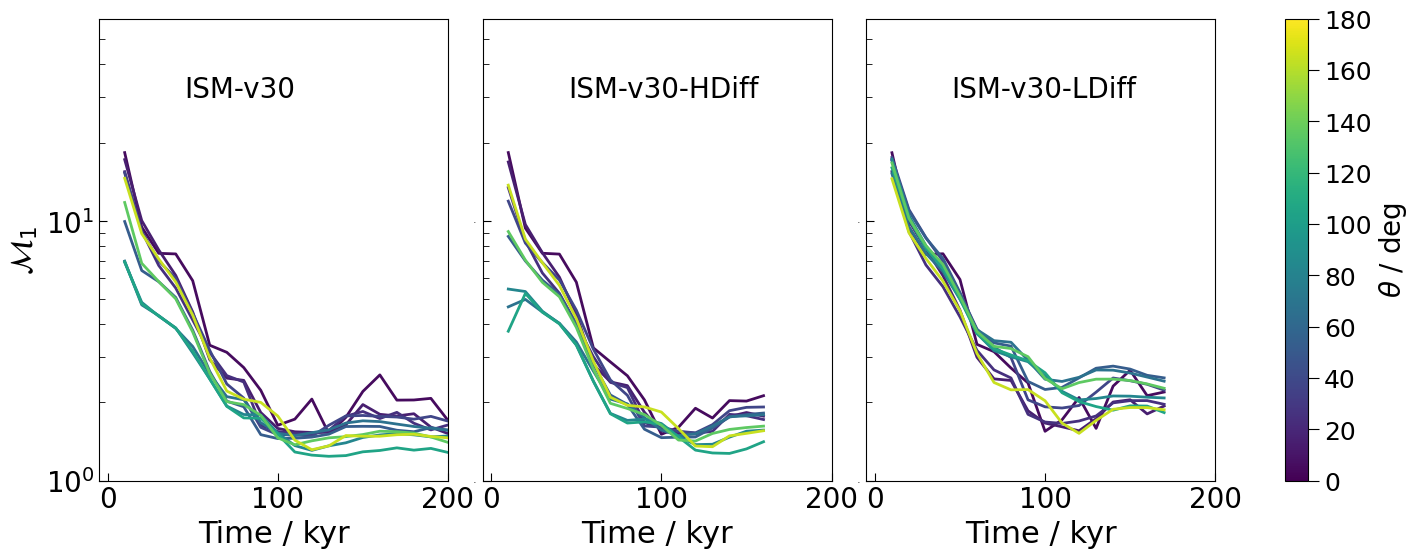

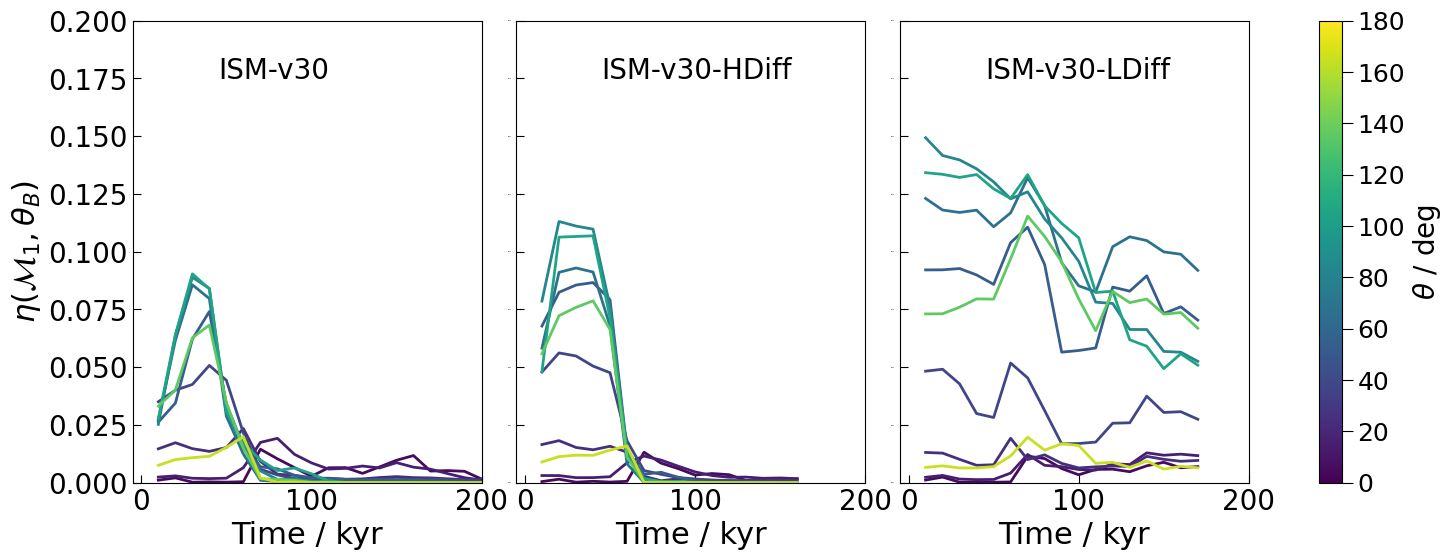

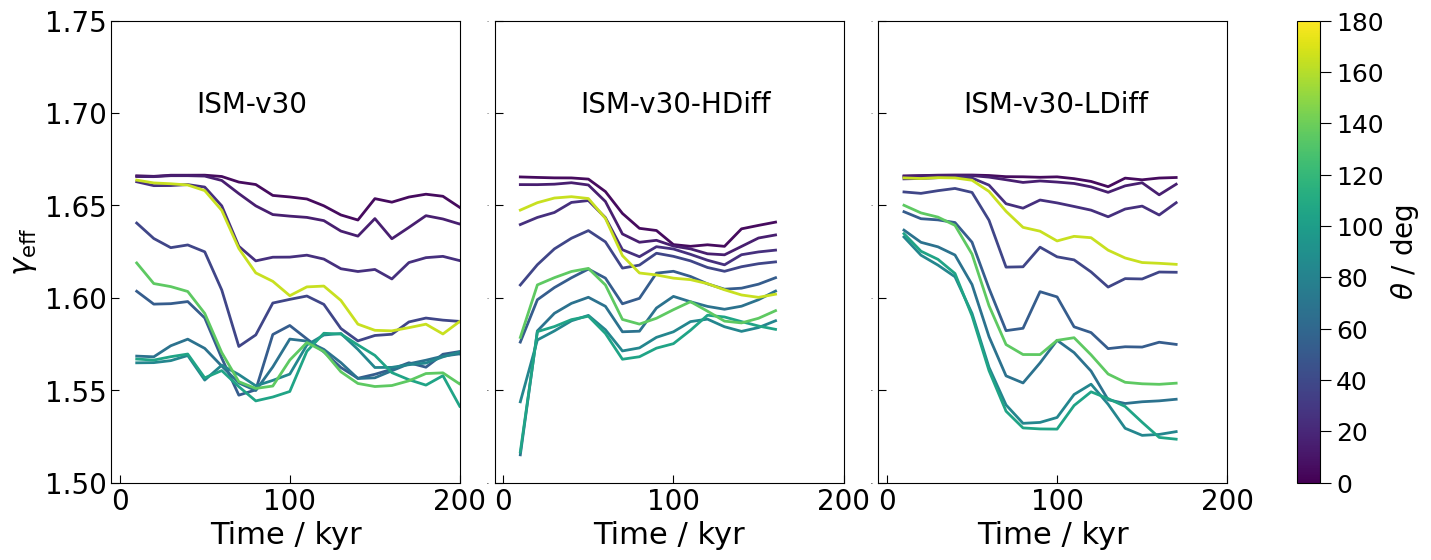

In [7]:
for p in params:
    fig = plt.figure(figsize=(18,6))
    gs = fig.add_gridspec(1, 3, hspace=0.1, wspace=0.1)
    axs = gs.subplots(sharex=True, sharey=False)

    with h5py.File(f"../data/polar_time_series_{shock_type}.h5", "r") as f:
        for ibs, diff_type in enumerate(["", "HDiff", "LDiff"]):
            bs_name = f"ISM-v30-{diff_type}" if diff_type != "" else "ISM-v30"
            
            times = (f[bs_name]["times"][()] * u.s).to(u.kyr)
            param_arr = f[bs_name][p][()]
            
            for itr, theta_range in enumerate(theta_ranges_sim):
                theta_mean = 0.5 * (theta_range[0] + theta_range[1])
                pl = axs[ibs].plot(times, param_arr[:,itr], color=theta_ranges_cmap(theta_ranges_norm(theta_mean)), lw=2.0)


            # labels
            axs[ibs].set_xlabel("Time / kyr", fontsize=22)
            if ibs == 0:
                axs[ibs].set_ylabel(field_labels[p], fontsize=22)

            # limits
            axs[ibs].set_xlim([-5, 200])
            axs[ibs].set_ylim(field_lims[p])

            # scales
            axs[ibs].set_yscale(field_scales[p])

            # ticks
            axs[ibs].tick_params(axis='x', direction="in", which='major', size=6, labelsize=20)
            axs[ibs].tick_params(axis='x', direction="in", which='minor', size=4, labelsize=16)

            # for y
            if ibs == 0:
                axs[ibs].tick_params(axis='y', direction="in", which='major', size=6, labelsize=20)
                axs[ibs].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=16)
            else:
                axs[ibs].tick_params(axis='y', direction="in", which='major', size=6, labelsize=0)
                axs[ibs].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=0)

            axs[ibs].annotate(f"{bs_name}", xy=(45, param_textpos[p]), fontsize=20, bbox=dict(facecolor='white', edgecolor='none'))

    # colorbar
    sm = cm.ScalarMappable(cmap=theta_ranges_cmap, norm=theta_ranges_norm)
    cbar = fig.colorbar(sm, ax=axs.ravel().tolist())
    cbar.ax.set_ylabel(r"$\theta$ / deg", fontsize=20)
    cbar.ax.tick_params(axis='both', which='major', size=8, labelsize=18)
    cbar.ax.tick_params(axis='both', which='minor', size=6, labelsize=18)

    fig.savefig(
        os.path.join(fig_type_dir, f"timeseries_{shock_type}_{p}.pdf"),
        dpi=200,
        bbox_inches="tight",
    )


#### Environment Dependent plots

In [8]:
param_textpos = {
    "encr" : 3e-11,
    "shma" : 30,
    "crac" : 0.175,
    "geff" : 1.7
}

param_lims = {
    "shma":[1.0, 75],
    "encr":[1e-15, 1e-9],
    "mgob" : [-5, 185.0],
    "crac": [0.0, 0.4],
    "geff":[1.3, 1.75],
}

fig_type_dir = os.path.join(fig_dir, "envs")
if not os.path.exists(fig_type_dir):
    os.mkdir(fig_type_dir)

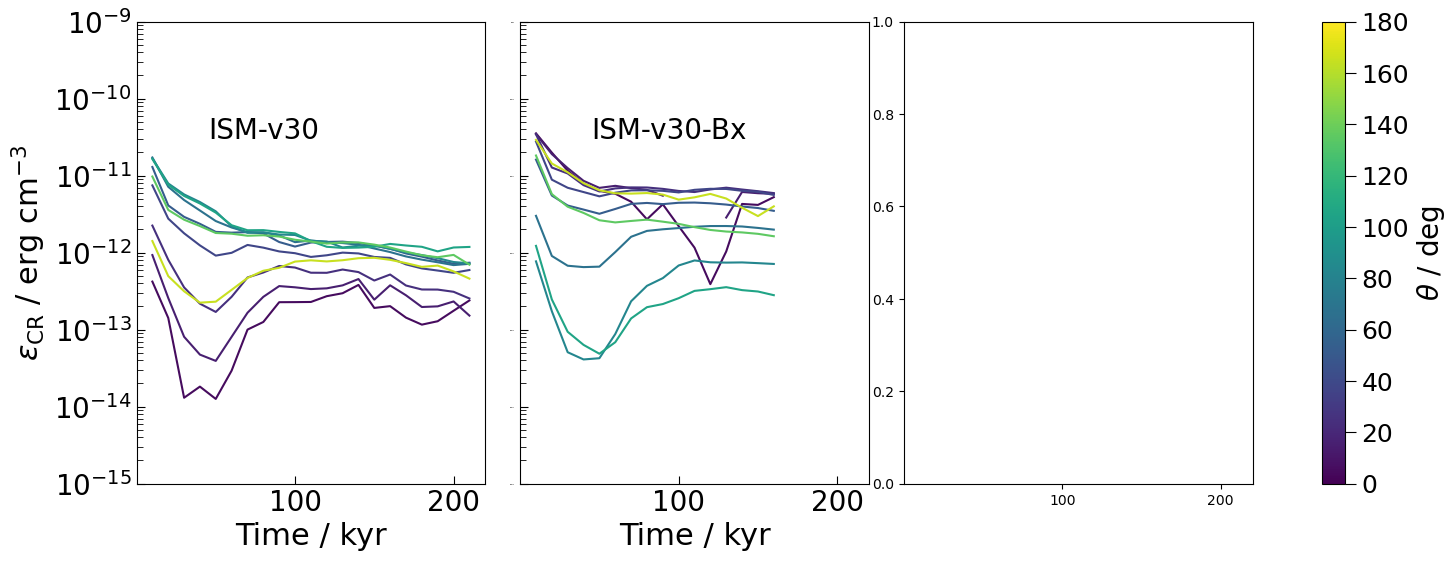

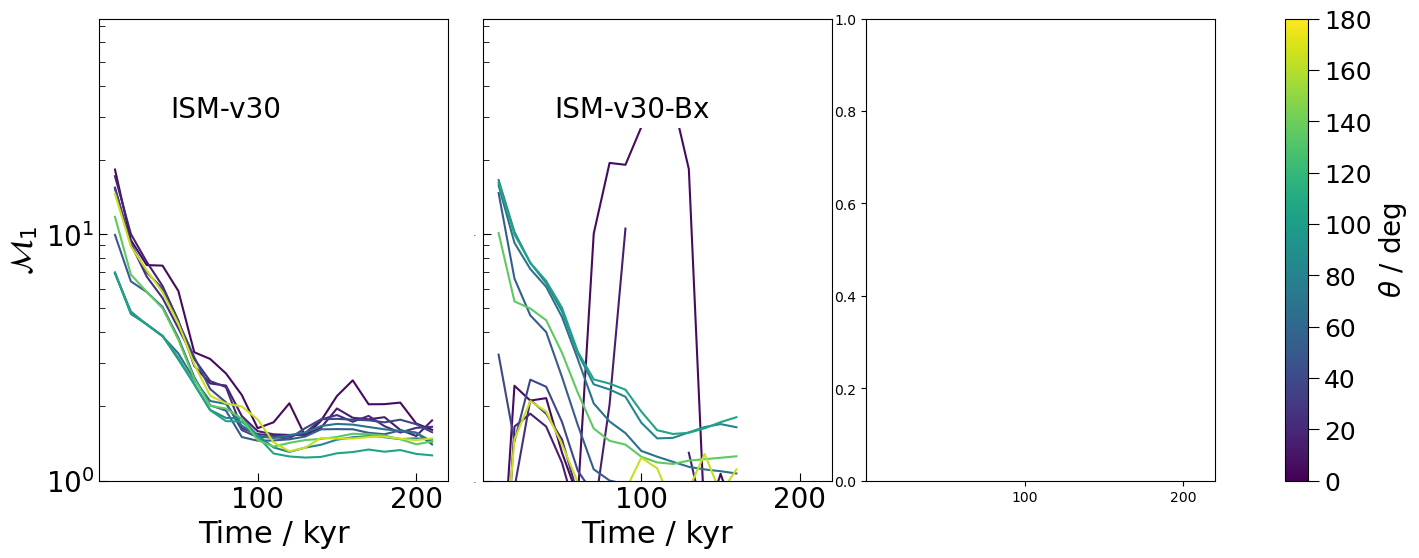

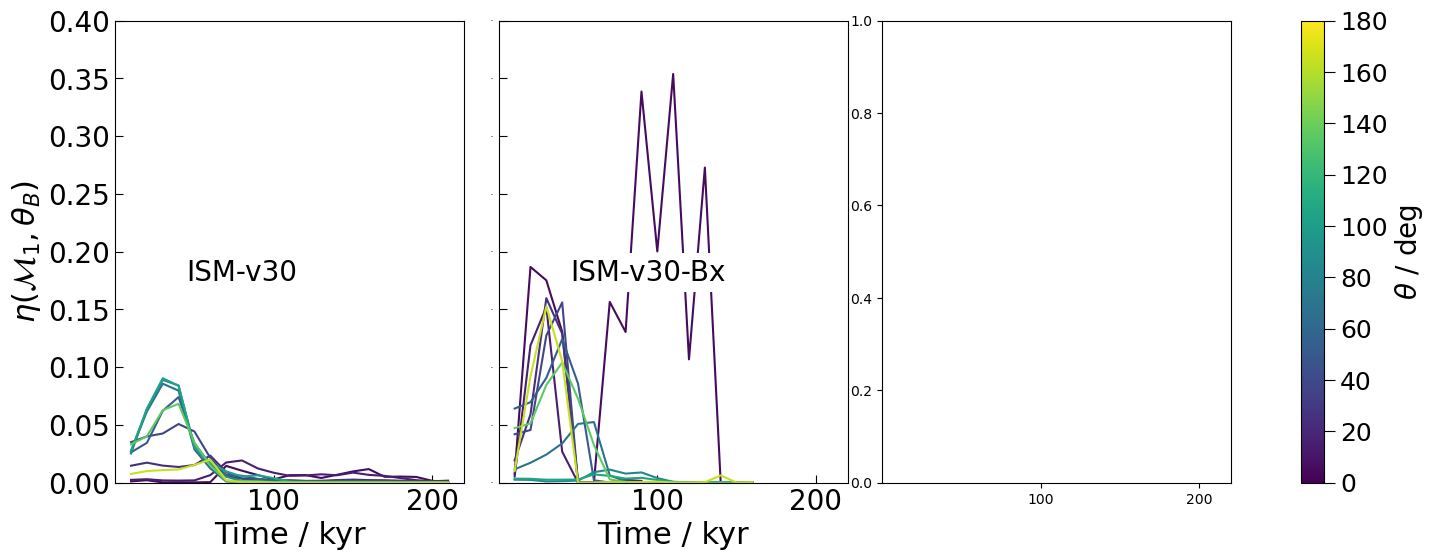

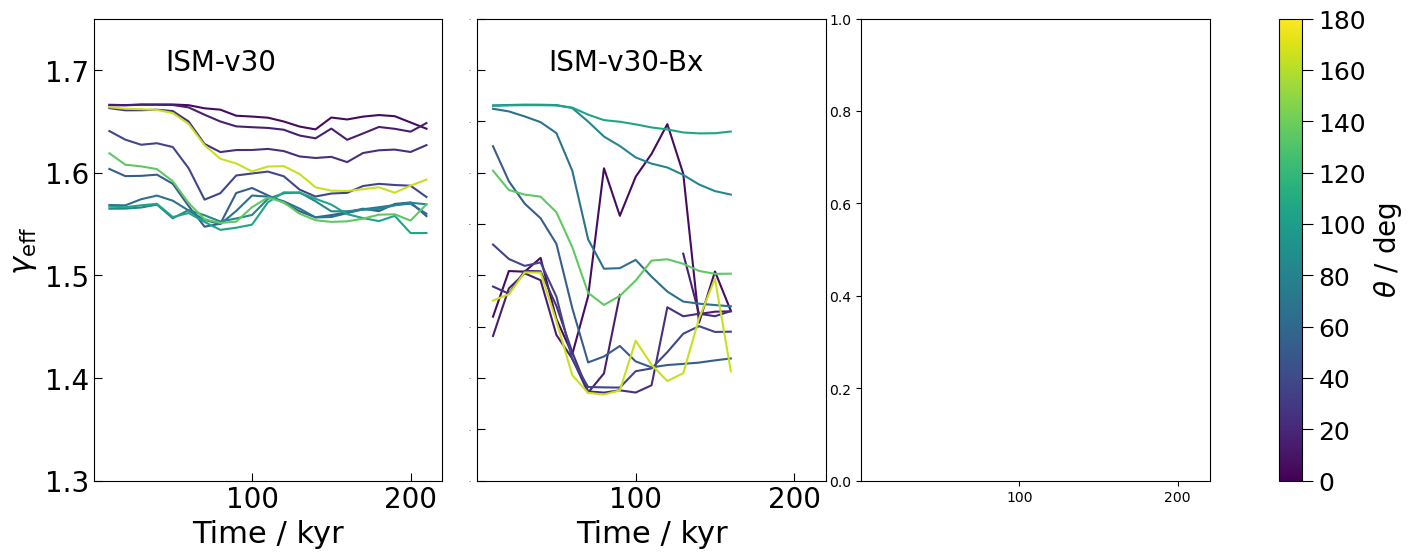

In [9]:
for p in params:
    fig = plt.figure(figsize=(18,6))
    gs = fig.add_gridspec(1, 3, hspace=0.1, wspace=0.1)
    axs = gs.subplots(sharex=True, sharey=False)

    with h5py.File(f"../data/polar_time_series_{shock_type}.h5", "r") as f:
        for ibs, bs_name in enumerate(["ISM-v30", "ISM-v30-Bx"]):
            
            times = (f[bs_name]["times"][()] * u.s).to(u.kyr)
            param_arr = f[bs_name][p][()]
            
            for itr, theta_range in enumerate(theta_ranges_sim):
                theta_mean = 0.5 * (theta_range[0] + theta_range[1])
                pl = axs[ibs].plot(times, param_arr[:,itr], color=theta_ranges_cmap(theta_ranges_norm(theta_mean)))


            # labels
            axs[ibs].set_xlabel("Time / kyr", fontsize=22)
            if ibs == 0:
                axs[ibs].set_ylabel(field_labels[p], fontsize=22)

            # limits
            # axs[ibs].set_xlim([-5, 120])
            axs[ibs].set_ylim(param_lims[p])

            # scales
            axs[ibs].set_yscale(field_scales[p])

            # ticks
            axs[ibs].tick_params(axis='x', direction="in", which='major', size=6, labelsize=20)
            axs[ibs].tick_params(axis='x', direction="in", which='minor', size=4, labelsize=16)

            # for y
            if ibs == 0:
                axs[ibs].tick_params(axis='y', direction="in", which='major', size=6, labelsize=20)
                axs[ibs].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=16)
            else:
                axs[ibs].tick_params(axis='y', direction="in", which='major', size=6, labelsize=0)
                axs[ibs].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=0)

            axs[ibs].annotate(f"{bs_name}", xy=(45, param_textpos[p]), fontsize=20, bbox=dict(facecolor='white', edgecolor='none'))

    # colorbar
    sm = cm.ScalarMappable(cmap=theta_ranges_cmap, norm=theta_ranges_norm)
    cbar = fig.colorbar(sm, ax=axs.ravel().tolist())
    cbar.ax.set_ylabel(r"$\theta$ / deg", fontsize=20)
    cbar.ax.tick_params(axis='both', which='major', size=8, labelsize=18)
    cbar.ax.tick_params(axis='both', which='minor', size=6, labelsize=18)

    fig.savefig(
        os.path.join(fig_type_dir, f"timeseries_{shock_type}_{p}.pdf"),
        dpi=200,
        bbox_inches="tight",
    )


### Plotting all at the same time

In [10]:
# theta_ranges = [(0,30), (30,60), (60,90), (90, 180)]
# params = ["encr", "shma", "crac", "geff"]
# shock_types = ["outer", "term"]

In [11]:
# shock_type_ls = ["-", "--"]
# bs_colors = [bowshock_config[k]["color"] for k in bowshock_config.keys()]

# bs_handles = []

# for ibs, bs_name in enumerate(list(bowshock_config.keys())):
#     bs_handles.append(
#         mlines.Line2D([0], [0],
#             color=bowshock_config[bs_name]["color"],
#             lw=2.0,
#             alpha=0.8,
#             label=bs_name)
#     )

# shck_handles = []
# for ish, shck in enumerate(shock_types):
#     shck_handles.append(
#         mlines.Line2D([0], [0],
#             color="k",
#             ls=shock_type_ls[ish],
#             lw=2.0,
#             alpha=0.8,
#             label=shock_labels[shck])
#     )

In [12]:
# fig = plt.figure(figsize=(30,20))
# gs = fig.add_gridspec( len(params), len(theta_ranges), hspace=0, wspace=0)
# axs = gs.subplots(sharex=True, sharey=False)


# for ish, shock_type in enumerate(shock_types):
#     with h5py.File(f"../data/polar_time_series_{shock_type}.h5", "r") as f:
#         for ibs, bs_name in enumerate(list(bowshock_config.keys())):
#             print(bs_name)
#             # if bs_name != "ISM-v30-LDiff":
#             #     continue
#             theta_ranges_sim = [(0, 10), (10,20),(20,30), (30, 45), (45,60), (60,75), (75,90), (90,120), (120,150),(150,180)]
#             times = (f[bs_name]["times"][()] * u.s).to(u.kyr)

#             # get minimum and maximum value in each range so that we can search index 
#             # corresponding to where min and max values are 
#             theta_minvals = [theta_ranges_sim[ith][0] for ith in range(len(theta_ranges_sim))]
#             theta_maxvals = [theta_ranges_sim[ith][1] for ith in range(len(theta_ranges_sim))]
#             print(theta_minvals, theta_maxvals)

#             for j, theta_range in enumerate(theta_ranges):

#                 # find indices where the theta centers cover
#                 theta_lidx = np.digitize(theta_range[0], theta_minvals, right=True)
#                 theta_uidx = np.digitize(theta_range[1], theta_maxvals, right=True)

#                 for i, p in enumerate(params):
#                     param_arr = f[bs_name][p][()][:,theta_lidx:theta_uidx+1]
#                     print(p, np.nanmax(param_arr), np.nanmin(param_arr))
#                     param_arr[np.isnan(param_arr)] = 0.0
#                     param_arr = np.mean(param_arr, axis=1)
                    
#                     axs[i,j].plot(times, param_arr, ls=shock_type_ls[ish], color=bs_colors[ibs])


#                     # labels
#                     axs[i,j].set_xlabel("Time / kyr", fontsize=22)
#                     if j == 0:
#                         axs[i,j].set_ylabel(field_labels[p], fontsize=22)

#                     # limits
#                     axs[i,j].set_xlim([-5, 200])
#                     axs[i,j].set_ylim(field_lims[p])

#                     # scales
#                     axs[i,j].set_yscale(field_scales[p])

#                     # ticks

#                     # for x
#                     if i == len(params) - 1:
#                         axs[i,j].tick_params(axis='x', direction="in", which='major', size=6, labelsize=20)
#                         axs[i,j].tick_params(axis='x', direction="in", which='minor', size=4, labelsize=16)
#                     else:
#                         axs[i,j].tick_params(axis='x', direction="in", which='major', size=6, labelsize=0)
#                         axs[i,j].tick_params(axis='x', direction="in", which='minor', size=4, labelsize=0)

#                     # for y
#                     if j == 0:
#                         axs[i,j].tick_params(axis='y', direction="in", which='major', size=6, labelsize=20)
#                         axs[i,j].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=16)
#                     else:
#                         axs[i,j].tick_params(axis='y', direction="in", which='major', size=6, labelsize=0)
#                         axs[i,j].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=0)

#                     # annotate theta ranges, only for top row (encr)
#                     if i == 0:
#                         axs[i,j].annotate(rf"${theta_range[0]}^\circ < \theta < {theta_range[1]}^\circ$", xy=(100, 1e-10), fontsize=15, bbox=dict(facecolor='white', edgecolor='none'))


# # handles
# bs_legend = fig.legend(handles=bs_handles, bbox_to_anchor=(0.68, 1.0), ncols=3, fontsize=20, framealpha=1.0, columnspacing=3.0, borderpad=0.7, borderaxespad=0.5, labelspacing=0.5, handletextpad=0.4)
# fig.add_artist(bs_legend)
# fig.legend(handles=shck_handles, bbox_to_anchor=(0.9, 1.0), ncols=1, fontsize=20, framealpha=1.0, columnspacing=3.0, borderpad=0.7, borderaxespad=0.5, labelspacing=0.5, handletextpad=0.4)
